In [1]:
file_path = r"C:\Users\Aini\OneDrive\Documents\Capstone\output.csv"

Unnamed: 0
Frames selected: [    0  6945 13890 20835 27780 34725 41670 48615 55560 62505]


C:\Users\Aini\AppData\Local\Temp\ipykernel_27848\1282121113.py:22: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["time_seconds"] = pd.to_timedelta(


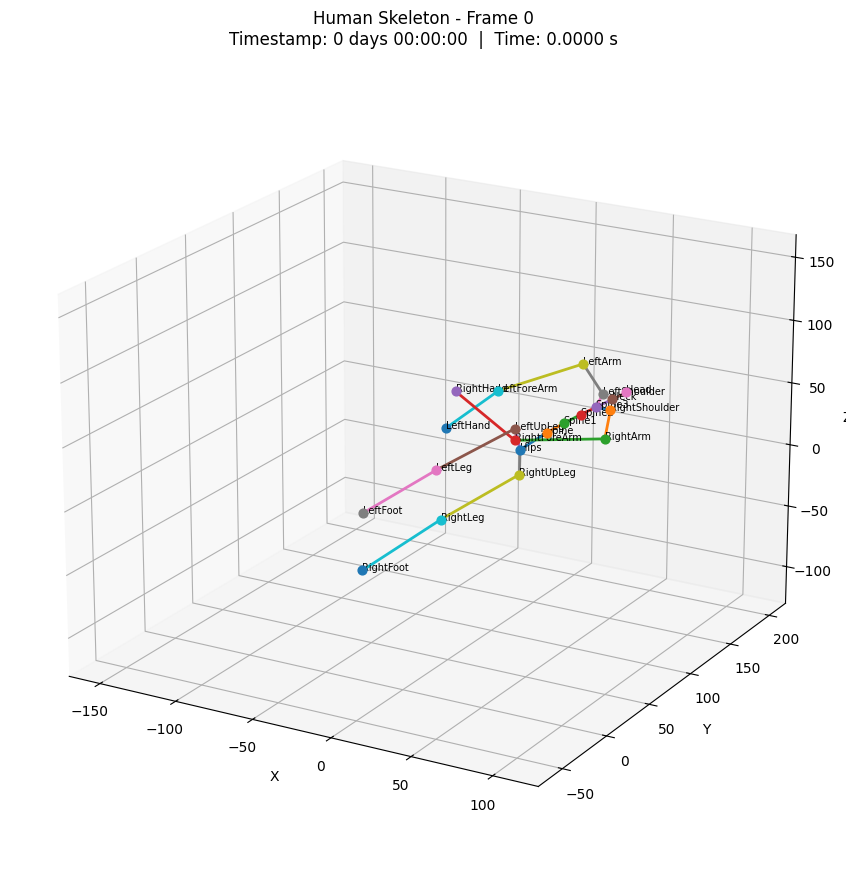

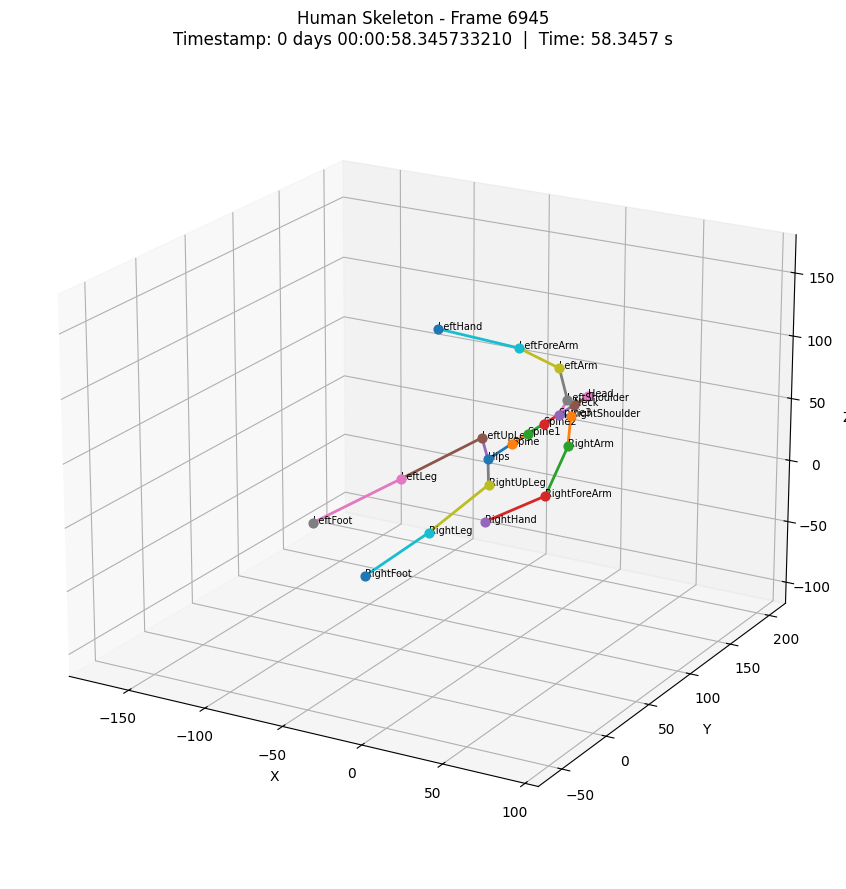

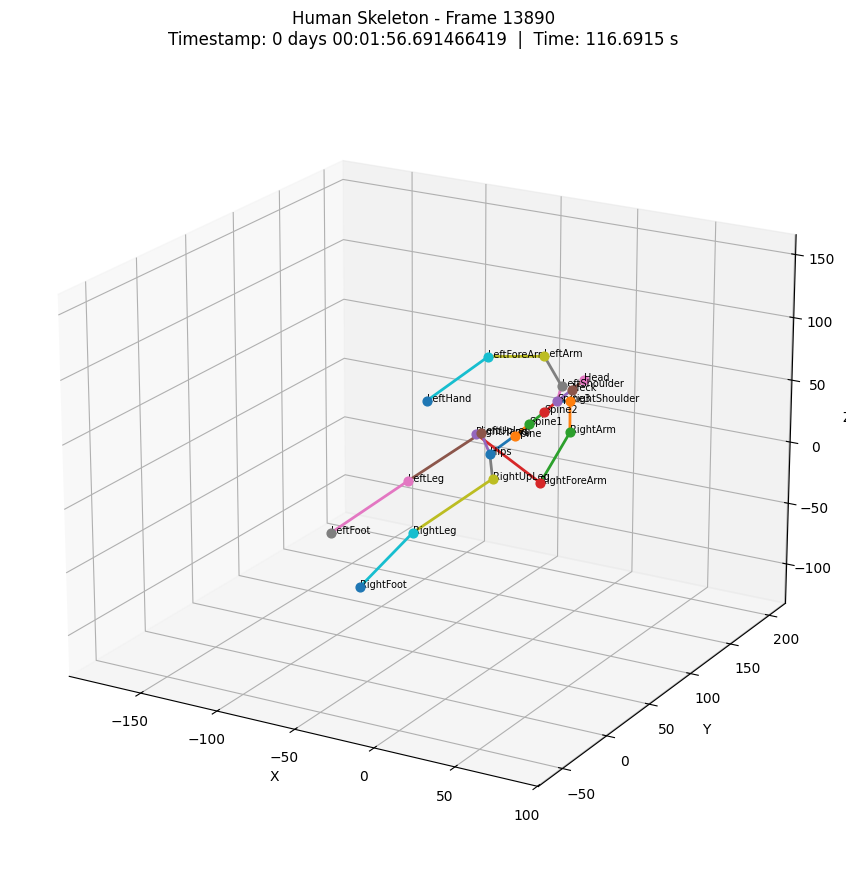

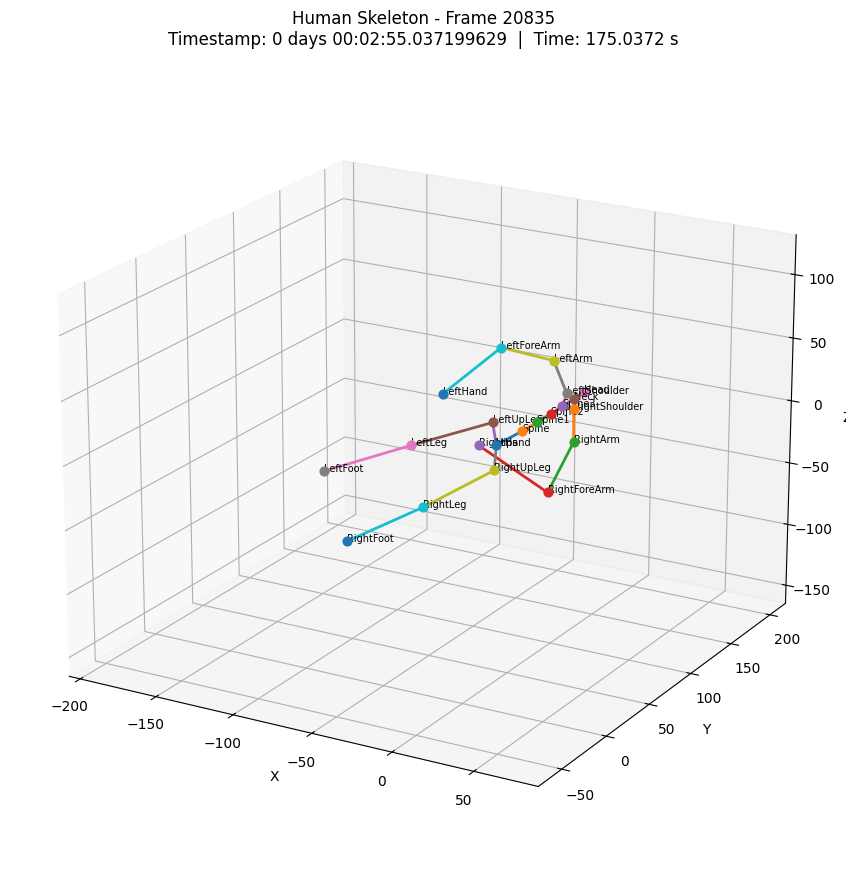

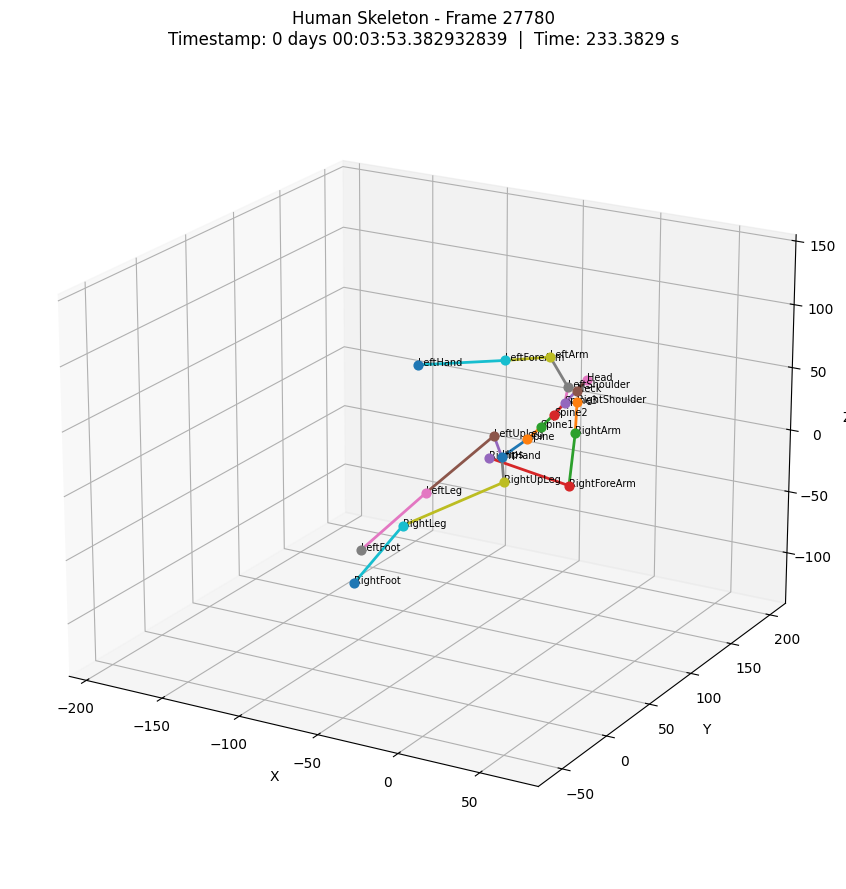

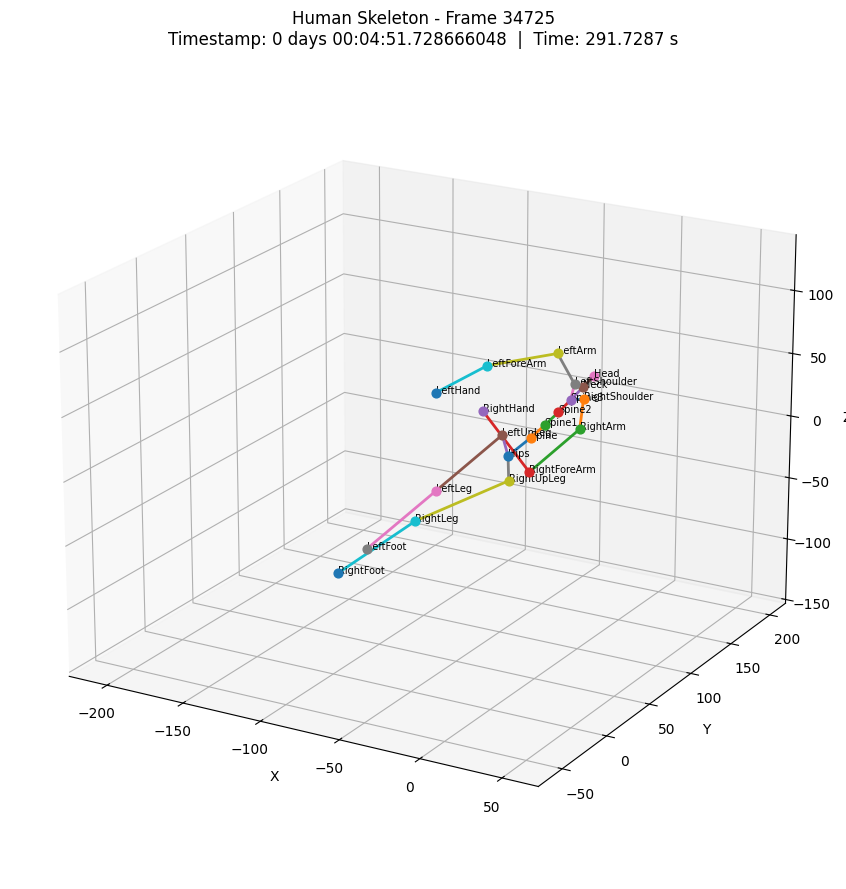

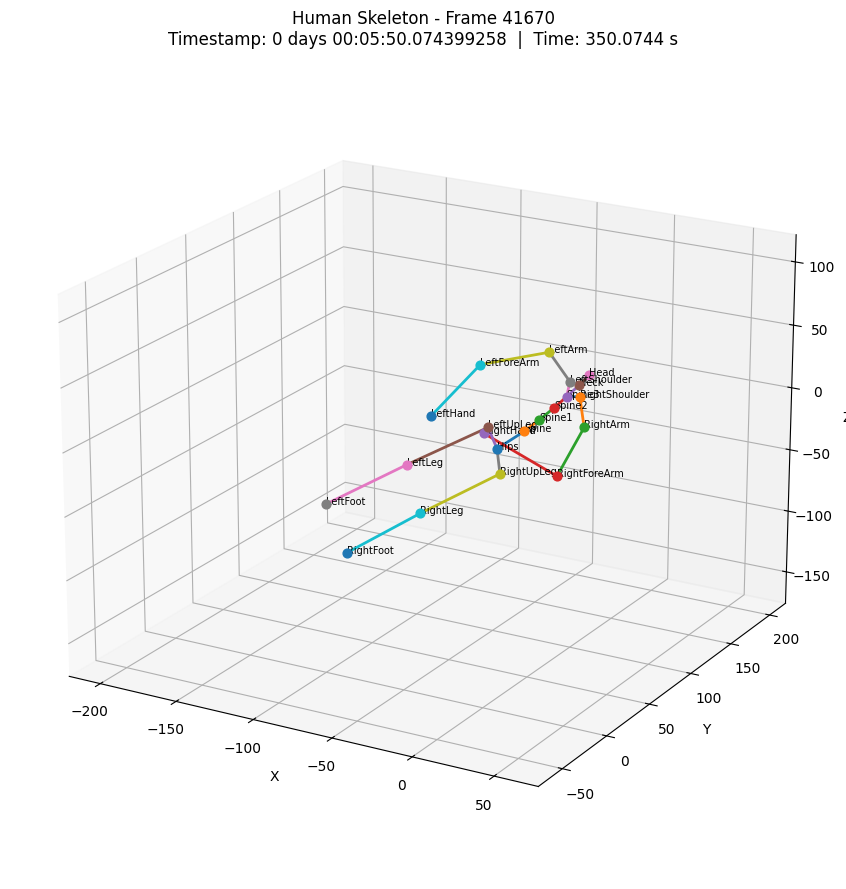

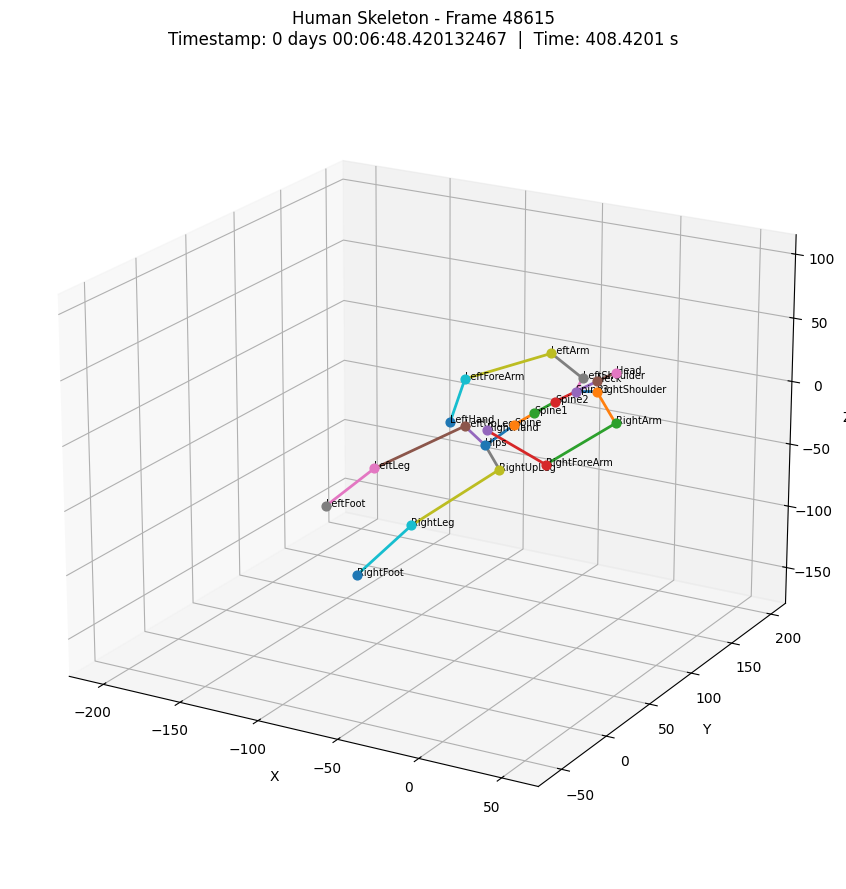

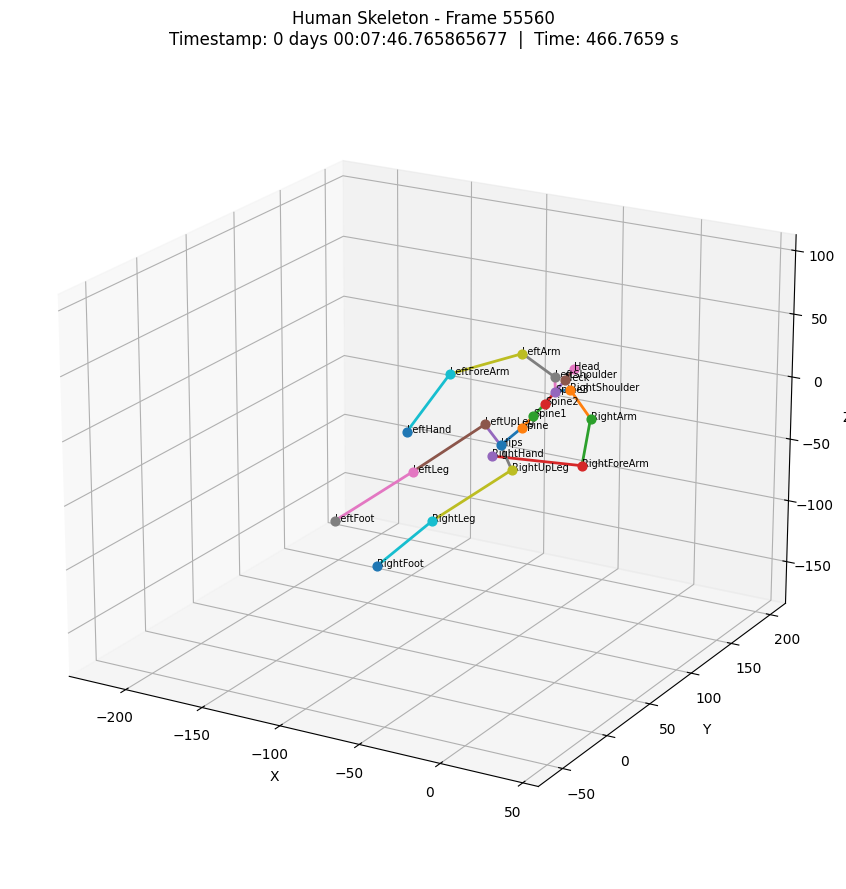

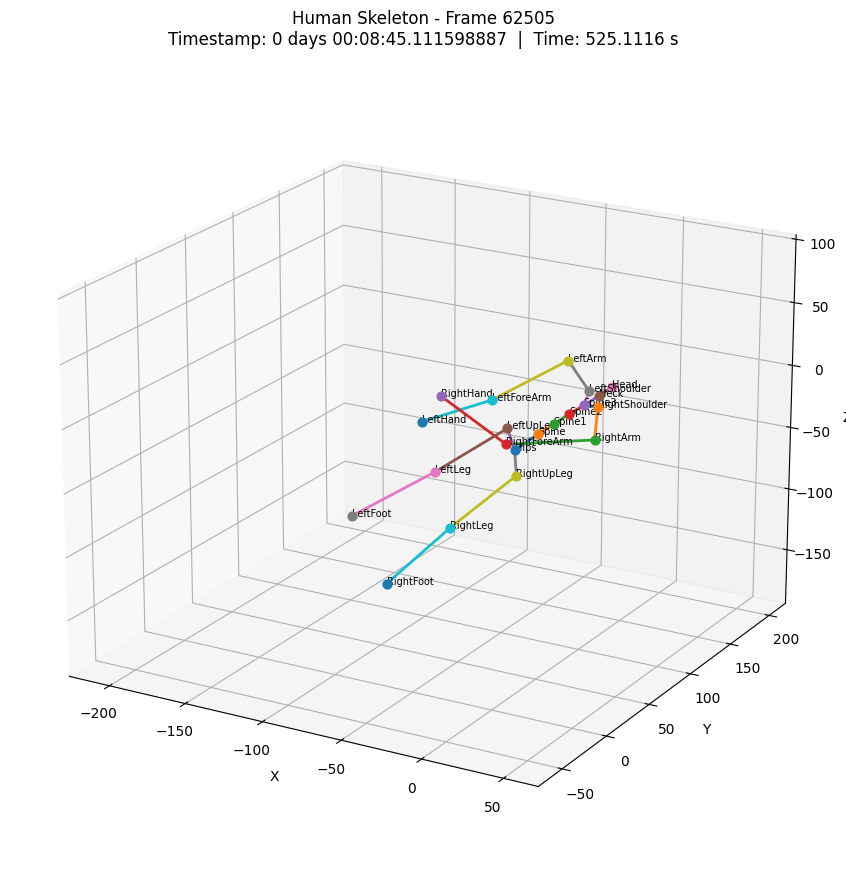


Done! Skeleton plots saved in: skeleton_plots


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# ============================================================
# 1. LOAD CSV
# ============================================================



df = pd.read_csv(file_path)

# If your timestamp is stored as a column called Timestamp,
# change this accordingly.
# For your current file, identify the timestamp column:
print(df.columns[0])

# Convert timestamp to seconds
timestamp_col = df.columns[0]

df["time_seconds"] = pd.to_timedelta(
    df[timestamp_col].astype(str)
).dt.total_seconds()


# ============================================================
# 2. DEFINE SKELETON CONNECTIONS
# ============================================================

connections = [
    # ----- Spine -----
    ("Hips", "Spine"),
    ("Spine", "Spine1"),
    ("Spine1", "Spine2"),
    ("Spine2", "Spine3"),
    ("Spine3", "Neck"),
    ("Neck", "Head"),

    # ----- Left arm -----
    ("Spine3", "LeftShoulder"),
    ("LeftShoulder", "LeftArm"),
    ("LeftArm", "LeftForeArm"),
    ("LeftForeArm", "LeftHand"),

    # ----- Right arm -----
    ("Spine3", "RightShoulder"),
    ("RightShoulder", "RightArm"),
    ("RightArm", "RightForeArm"),
    ("RightForeArm", "RightHand"),

    # ----- Left leg -----
    ("Hips", "LeftUpLeg"),
    ("LeftUpLeg", "LeftLeg"),
    ("LeftLeg", "LeftFoot"),

    # ----- Right leg -----
    ("Hips", "RightUpLeg"),
    ("RightUpLeg", "RightLeg"),
    ("RightLeg", "RightFoot"),
]


# ============================================================
# 3. FUNCTION TO GET JOINT POSITION
# ============================================================

def get_joint_position(row, joint):

    x_col = f"{joint}_Xposition"
    y_col = f"{joint}_Yposition"
    z_col = f"{joint}_Zposition"

    if x_col not in df.columns:
        return None

    if y_col not in df.columns:
        return None

    if z_col not in df.columns:
        return None

    return np.array([
        row[x_col],
        row[y_col],
        row[z_col]
    ], dtype=float)


# ============================================================
# 4. SELECT 10 TIMESTAMPS
# ============================================================

n_frames = len(df)

# If >= 10 frames, choose 10 evenly distributed frames.
# If < 10 frames, use every available frame.
if n_frames >= 10:
    frame_indices = np.linspace(
        0,
        n_frames - 1,
        10,
        dtype=int
    )
else:
    frame_indices = np.arange(n_frames)

print("Frames selected:", frame_indices)


# ============================================================
# 5. CREATE OUTPUT DIRECTORY
# ============================================================

output_dir = "skeleton_plots"
os.makedirs(output_dir, exist_ok=True)


# ============================================================
# 6. GENERATE SKELETON PLOTS
# ============================================================

for plot_number, frame_idx in enumerate(frame_indices, start=1):

    row = df.iloc[frame_idx]

    fig = plt.figure(figsize=(9, 9))
    ax = fig.add_subplot(111, projection="3d")

    # --------------------------------------------------------
    # Plot joints
    # --------------------------------------------------------

    joint_positions = {}

    for connection in connections:

        for joint in connection:

            if joint not in joint_positions:

                position = get_joint_position(row, joint)

                if position is not None and np.all(np.isfinite(position)):
                    joint_positions[joint] = position

    # Plot individual joints
    for joint, position in joint_positions.items():

        ax.scatter(
            position[0],
            position[1],
            position[2],
            s=40
        )

        ax.text(
            position[0],
            position[1],
            position[2],
            joint,
            fontsize=7
        )


    # --------------------------------------------------------
    # Draw bones
    # --------------------------------------------------------

    for joint1, joint2 in connections:

        if joint1 not in joint_positions:
            continue

        if joint2 not in joint_positions:
            continue

        p1 = joint_positions[joint1]
        p2 = joint_positions[joint2]

        ax.plot(
            [p1[0], p2[0]],
            [p1[1], p2[1]],
            [p1[2], p2[2]],
            linewidth=2
        )


    # --------------------------------------------------------
    # Timestamp
    # --------------------------------------------------------

    timestamp = df.iloc[frame_idx][timestamp_col]
    time_sec = df.iloc[frame_idx]["time_seconds"]

    ax.set_title(
        f"Human Skeleton - Frame {frame_idx}\n"
        f"Timestamp: {timestamp}  |  Time: {time_sec:.4f} s"
    )


    # --------------------------------------------------------
    # Axis labels
    # --------------------------------------------------------

    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")


    # --------------------------------------------------------
    # Make axes approximately equal
    # --------------------------------------------------------

    all_positions = np.array(
        list(joint_positions.values())
    )

    if len(all_positions) > 0:

        x_min, y_min, z_min = all_positions.min(axis=0)
        x_max, y_max, z_max = all_positions.max(axis=0)

        max_range = max(
            x_max - x_min,
            y_max - y_min,
            z_max - z_min
        ) / 2

        x_mid = (x_max + x_min) / 2
        y_mid = (y_max + y_min) / 2
        z_mid = (z_max + z_min) / 2

        ax.set_xlim(x_mid - max_range, x_mid + max_range)
        ax.set_ylim(y_mid - max_range, y_mid + max_range)
        ax.set_zlim(z_mid - max_range, z_mid + max_range)


    # --------------------------------------------------------
    # Viewing angle
    # --------------------------------------------------------

    ax.view_init(
        elev=20,
        azim=-60
    )

    plt.tight_layout()


    # --------------------------------------------------------
    # SAVE
    # --------------------------------------------------------

    output_file = os.path.join(
        output_dir,
        f"skeleton_frame_{plot_number:02d}.png"
    )

    plt.savefig(
        output_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


print(
    f"\nDone! Skeleton plots saved in: {output_dir}"
)

Unnamed: 0


C:\Users\Aini\AppData\Local\Temp\ipykernel_2936\3576280891.py:22: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["time_seconds"] = pd.to_timedelta(


Frames selected: [    0  6945 13890 20835 27780 34725 41670 48615 55560 62505]


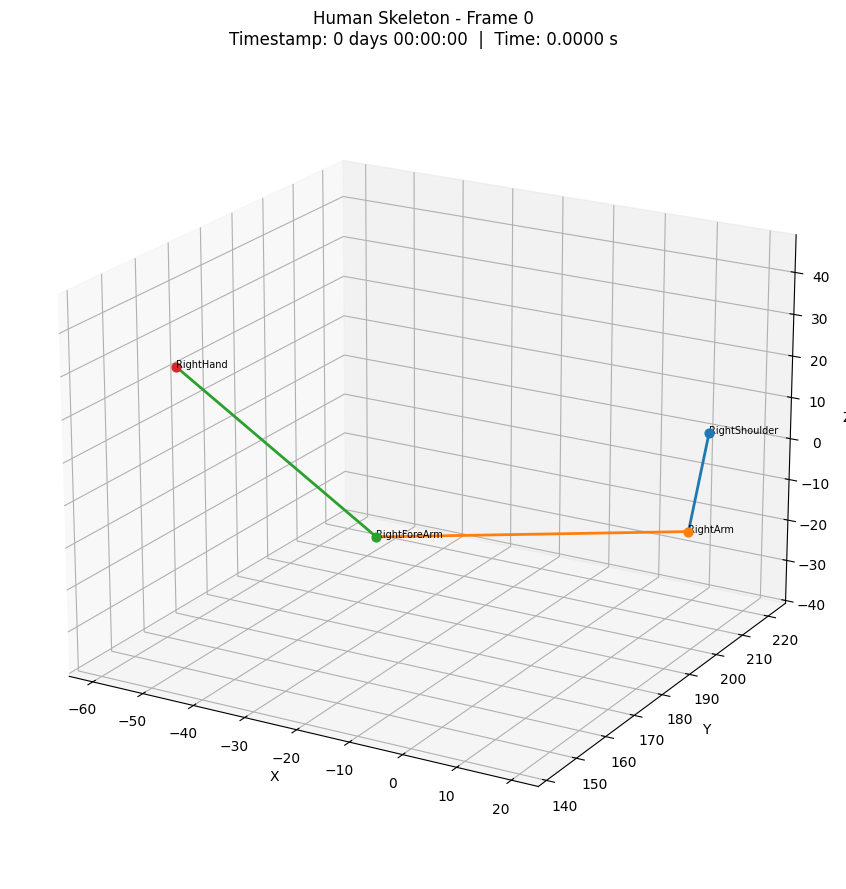

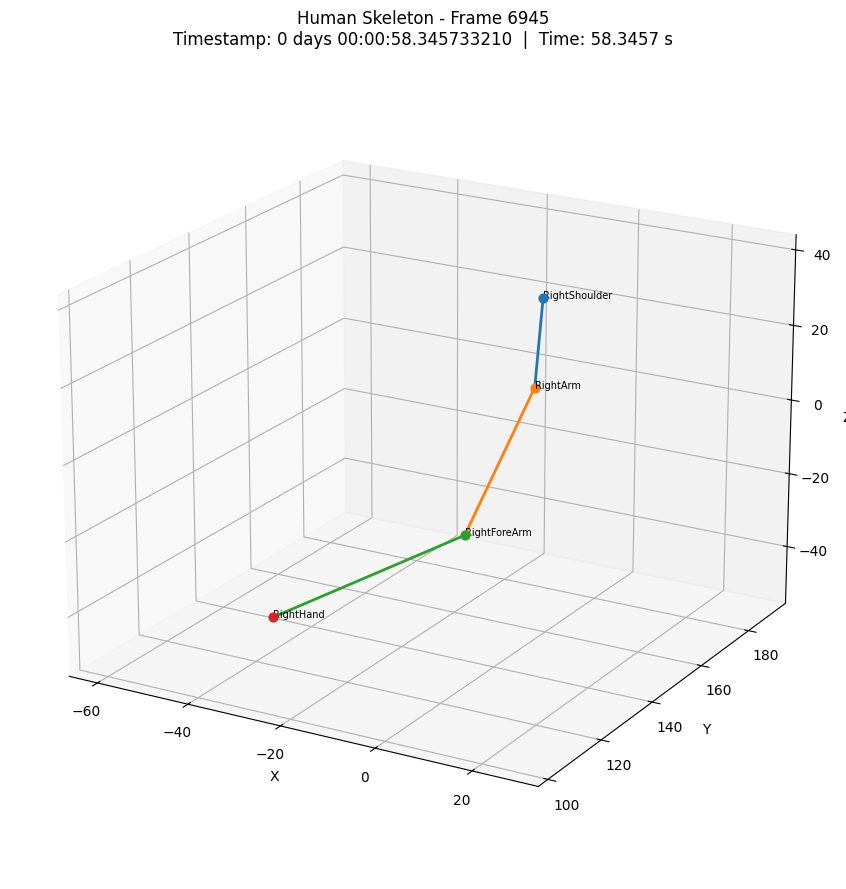

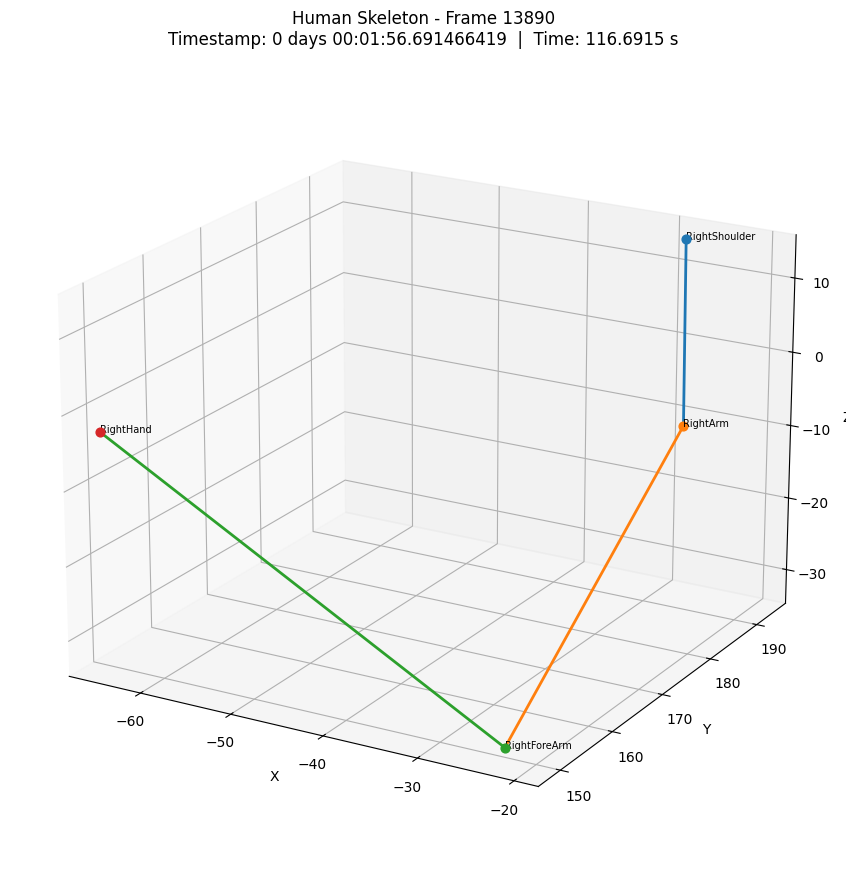

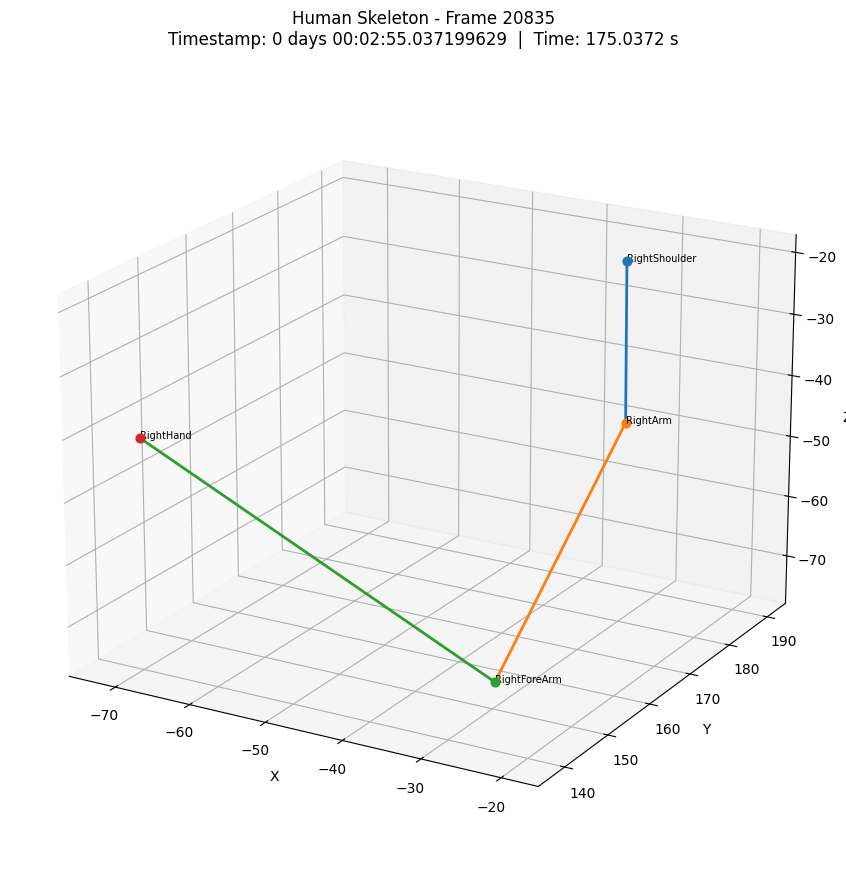

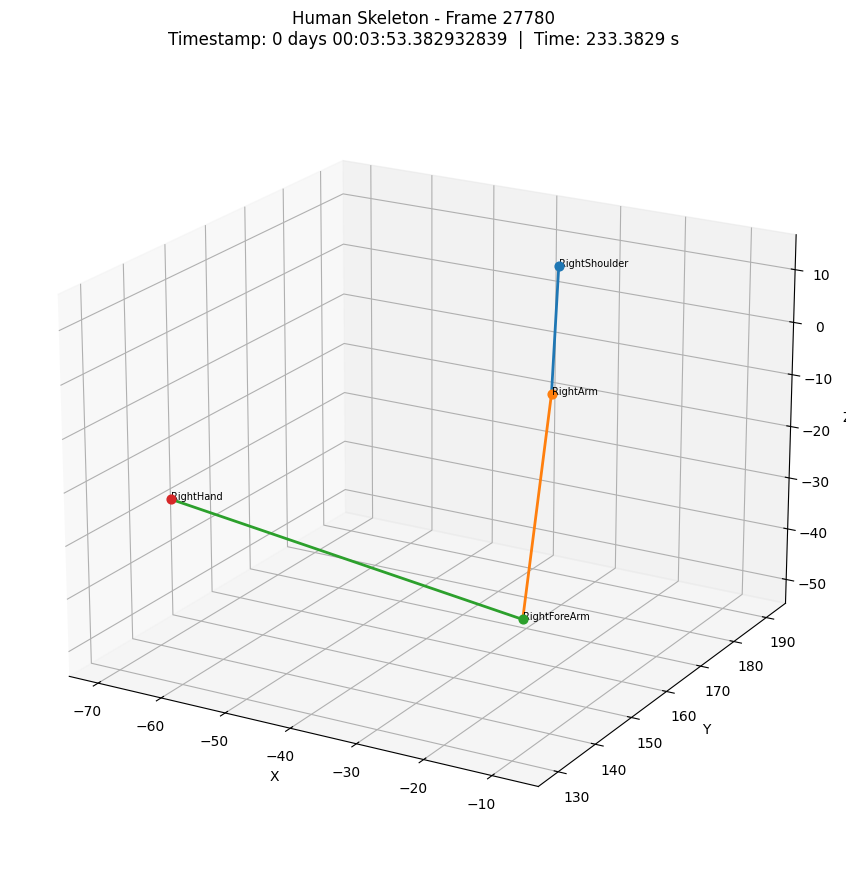

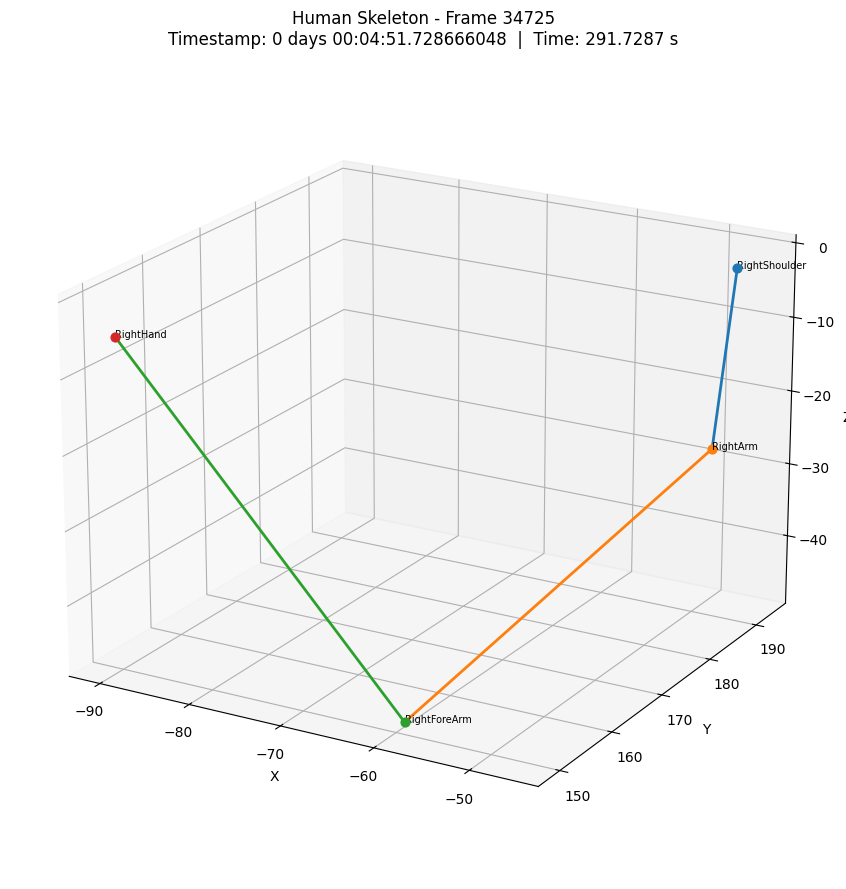

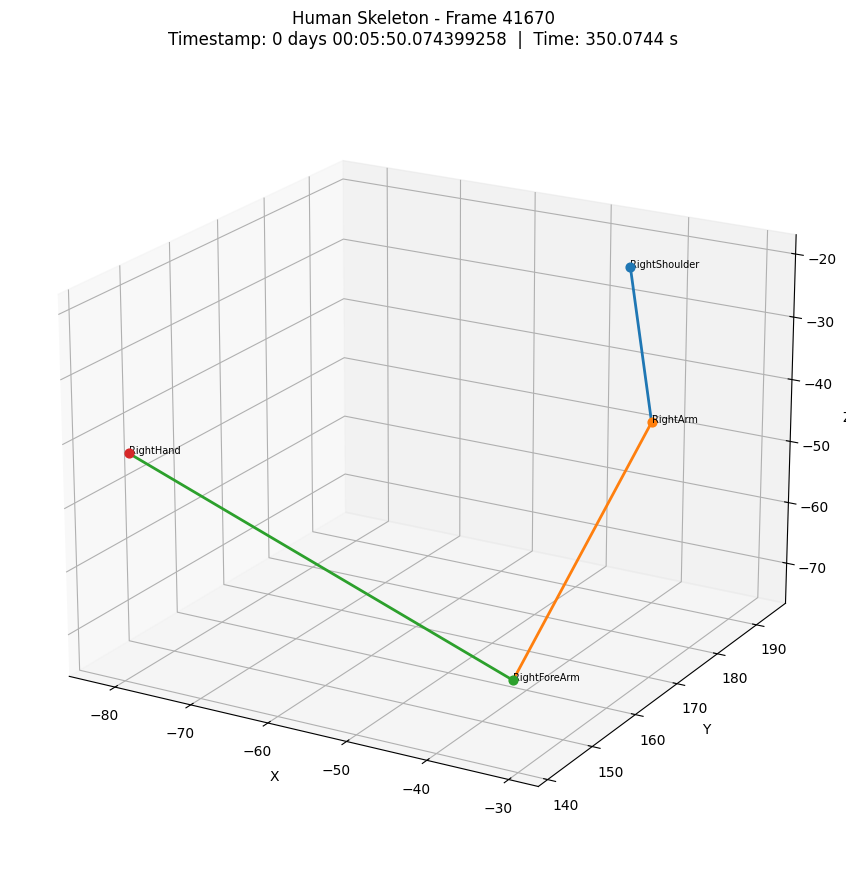

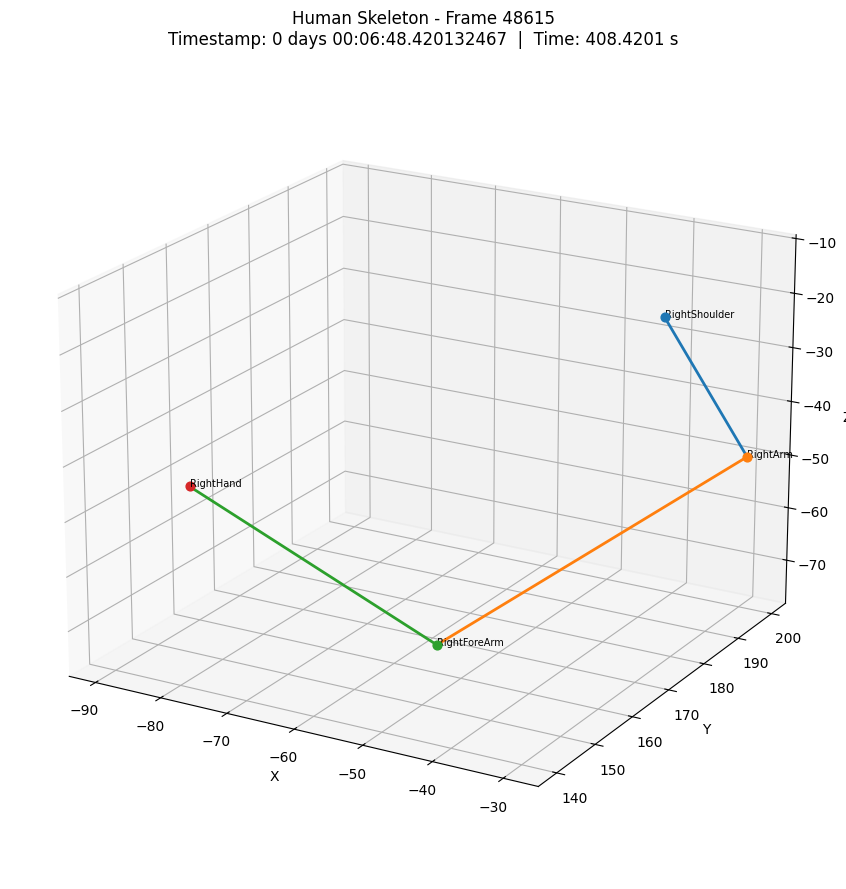

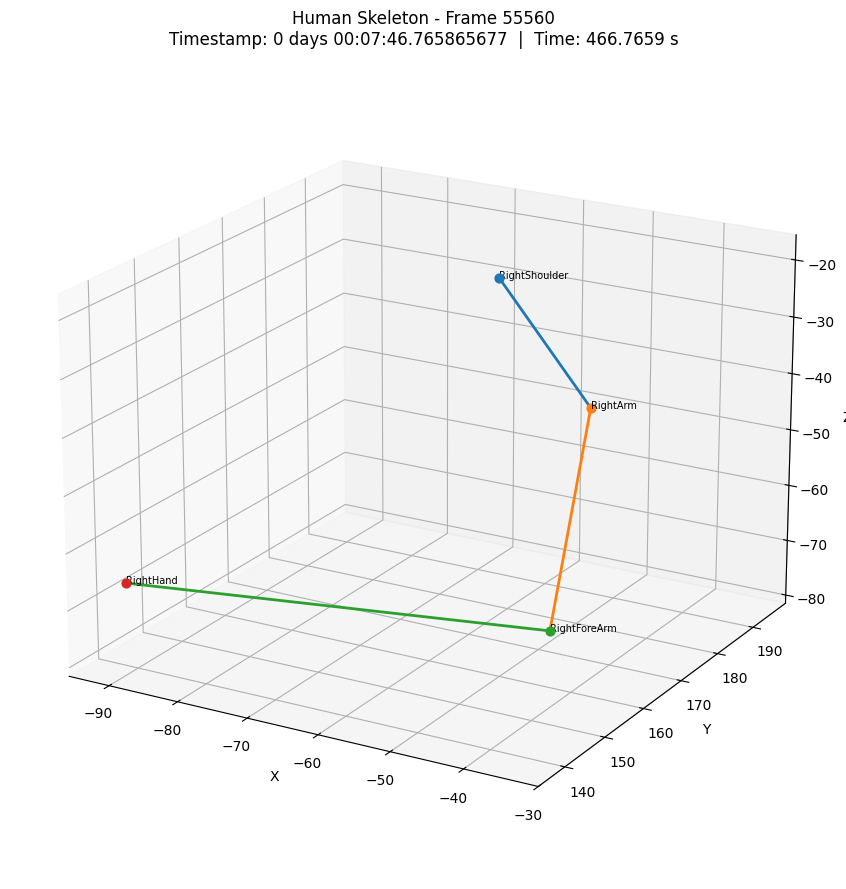

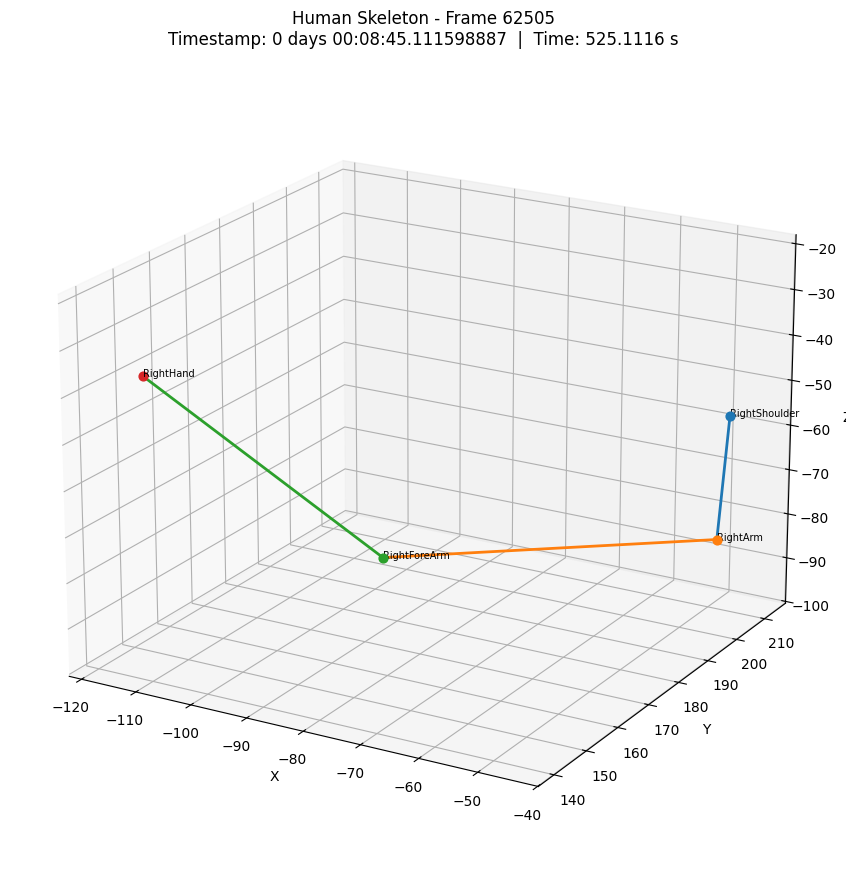


Done! Skeleton plots saved in: skeleton_plots


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# ============================================================
# 1. LOAD CSV
# ============================================================



df = pd.read_csv(file_path)

# If your timestamp is stored as a column called Timestamp,
# change this accordingly.
# For your current file, identify the timestamp column:
print(df.columns[0])

# Convert timestamp to seconds
timestamp_col = df.columns[0]

df["time_seconds"] = pd.to_timedelta(
    df[timestamp_col].astype(str)
).dt.total_seconds()


# ============================================================
# 2. DEFINE SKELETON CONNECTIONS
# ============================================================

connections = [
    

    # ----- Right arm -----
    
    ("RightShoulder", "RightArm"),
    ("RightArm", "RightForeArm"),
    ("RightForeArm", "RightHand"),

]


# ============================================================
# 3. FUNCTION TO GET JOINT POSITION
# ============================================================

def get_joint_position(row, joint):

    x_col = f"{joint}_Xposition"
    y_col = f"{joint}_Yposition"
    z_col = f"{joint}_Zposition"

    if x_col not in df.columns:
        return None

    if y_col not in df.columns:
        return None

    if z_col not in df.columns:
        return None

    return np.array([
        row[x_col],
        row[y_col],
        row[z_col]
    ], dtype=float)


# ============================================================
# 4. SELECT 10 TIMESTAMPS
# ============================================================

n_frames = len(df)

# If >= 10 frames, choose 10 evenly distributed frames.
# If < 10 frames, use every available frame.
if n_frames >= 10:
    frame_indices = np.linspace(
        0,
        n_frames - 1,
        10,
        dtype=int
    )
else:
    frame_indices = np.arange(n_frames)

print("Frames selected:", frame_indices)


# ============================================================
# 5. CREATE OUTPUT DIRECTORY
# ============================================================

output_dir = "skeleton_plots"
os.makedirs(output_dir, exist_ok=True)


# ============================================================
# 6. GENERATE SKELETON PLOTS
# ============================================================

for plot_number, frame_idx in enumerate(frame_indices, start=1):

    row = df.iloc[frame_idx]

    fig = plt.figure(figsize=(9, 9))
    ax = fig.add_subplot(111, projection="3d")

    # --------------------------------------------------------
    # Plot joints
    # --------------------------------------------------------

    joint_positions = {}

    for connection in connections:

        for joint in connection:

            if joint not in joint_positions:

                position = get_joint_position(row, joint)

                if position is not None and np.all(np.isfinite(position)):
                    joint_positions[joint] = position

    # Plot individual joints
    for joint, position in joint_positions.items():

        ax.scatter(
            position[0],
            position[1],
            position[2],
            s=40
        )

        ax.text(
            position[0],
            position[1],
            position[2],
            joint,
            fontsize=7
        )


    # --------------------------------------------------------
    # Draw bones
    # --------------------------------------------------------

    for joint1, joint2 in connections:

        if joint1 not in joint_positions:
            continue

        if joint2 not in joint_positions:
            continue

        p1 = joint_positions[joint1]
        p2 = joint_positions[joint2]

        ax.plot(
            [p1[0], p2[0]],
            [p1[1], p2[1]],
            [p1[2], p2[2]],
            linewidth=2
        )


    # --------------------------------------------------------
    # Timestamp
    # --------------------------------------------------------

    timestamp = df.iloc[frame_idx][timestamp_col]
    time_sec = df.iloc[frame_idx]["time_seconds"]

    ax.set_title(
        f"Human Skeleton - Frame {frame_idx}\n"
        f"Timestamp: {timestamp}  |  Time: {time_sec:.4f} s"
    )


    # --------------------------------------------------------
    # Axis labels
    # --------------------------------------------------------

    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")


    # --------------------------------------------------------
    # Make axes approximately equal
    # --------------------------------------------------------

    all_positions = np.array(
        list(joint_positions.values())
    )

    if len(all_positions) > 0:

        x_min, y_min, z_min = all_positions.min(axis=0)
        x_max, y_max, z_max = all_positions.max(axis=0)

        max_range = max(
            x_max - x_min,
            y_max - y_min,
            z_max - z_min
        ) / 2

        x_mid = (x_max + x_min) / 2
        y_mid = (y_max + y_min) / 2
        z_mid = (z_max + z_min) / 2

        ax.set_xlim(x_mid - max_range, x_mid + max_range)
        ax.set_ylim(y_mid - max_range, y_mid + max_range)
        ax.set_zlim(z_mid - max_range, z_mid + max_range)


    # --------------------------------------------------------
    # Viewing angle
    # --------------------------------------------------------

    ax.view_init(
        elev=20,
        azim=-60
    )

    plt.tight_layout()


    # --------------------------------------------------------
    # SAVE
    # --------------------------------------------------------

    output_file = os.path.join(
        output_dir,
        f"skeleton_frame_{plot_number:02d}.png"
    )

    plt.savefig(
        output_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


print(
    f"\nDone! Skeleton plots saved in: {output_dir}"
)

In [11]:
file_path = r"C:\Users\Aini\OneDrive\Documents\Capstone\code\output4.csv"

Unnamed: 0


C:\Users\Aini\AppData\Local\Temp\ipykernel_2936\1282121113.py:22: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["time_seconds"] = pd.to_timedelta(
C:\Users\Aini\AppData\Local\Temp\ipykernel_2936\1282121113.py:234: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(x_mid - max_range, x_mid + max_range)
C:\Users\Aini\AppData\Local\Temp\ipykernel_2936\1282121113.py:235: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set_ylim(y_mid - max_range, y_mid + max_range)
C:\Users\Aini\AppData\Local\Temp\ipykernel_2936\1282121113.py:236: UserWarning: Attempting to set identical low and high zlims makes transformation

Frames selected: [    0  6945 13890 20835 27780 34725 41670 48615 55560 62505]


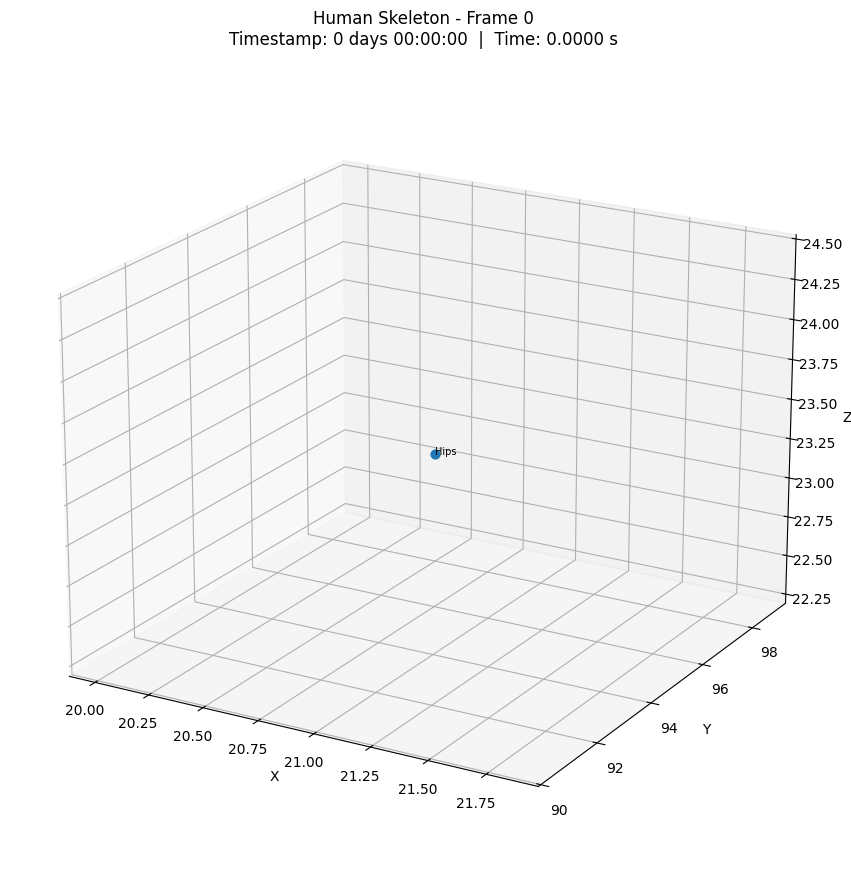

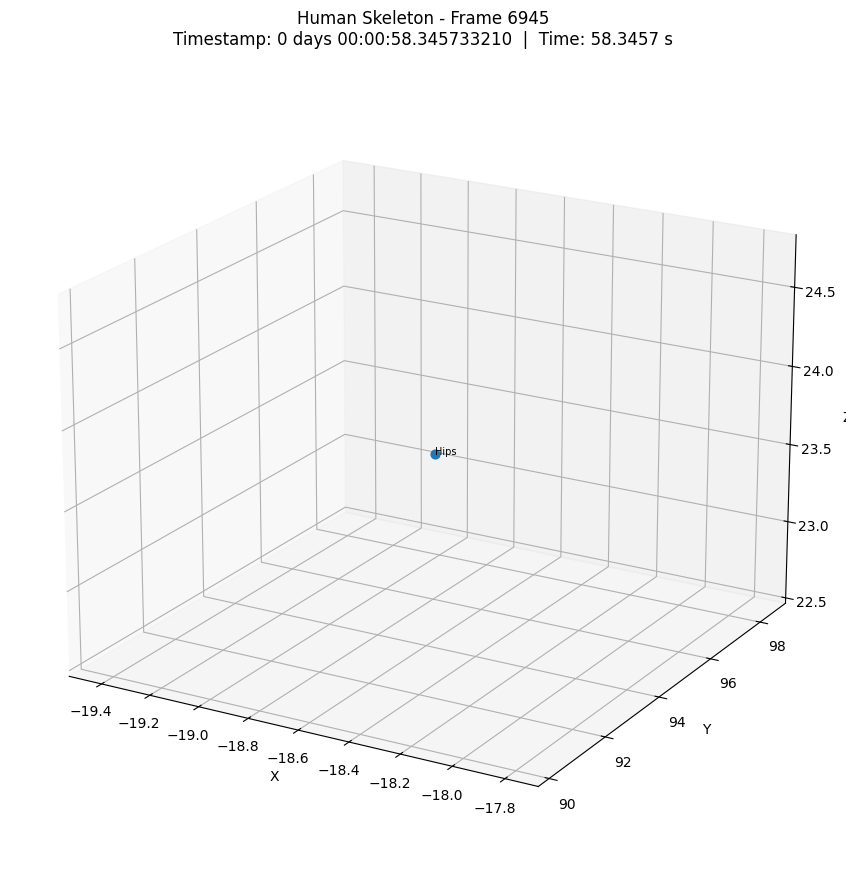

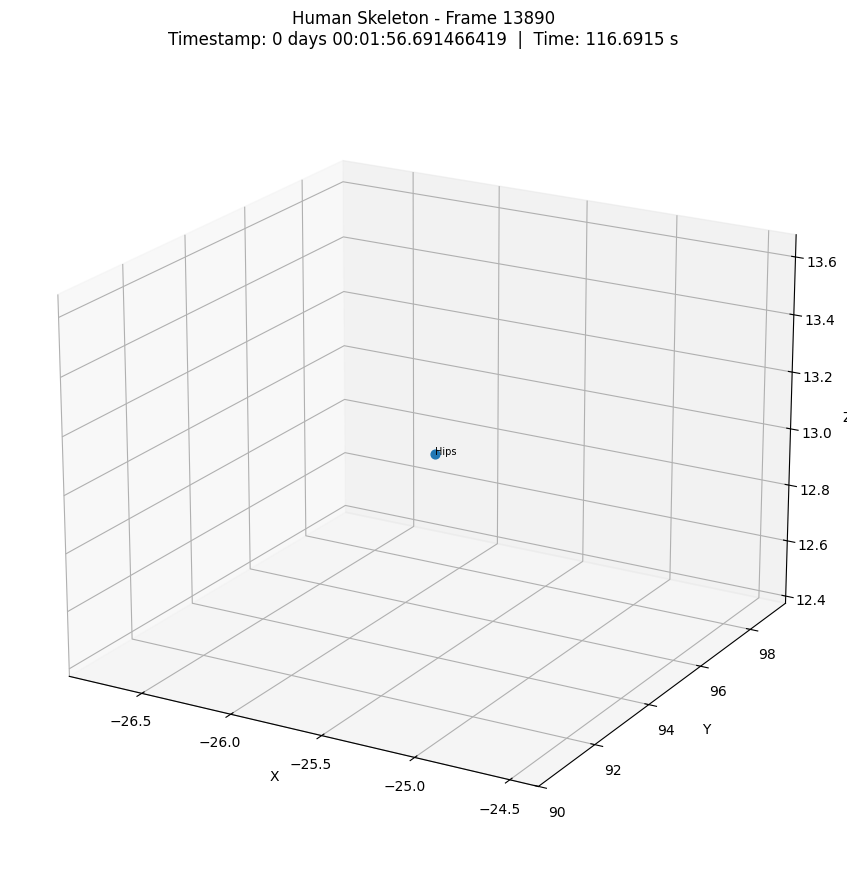

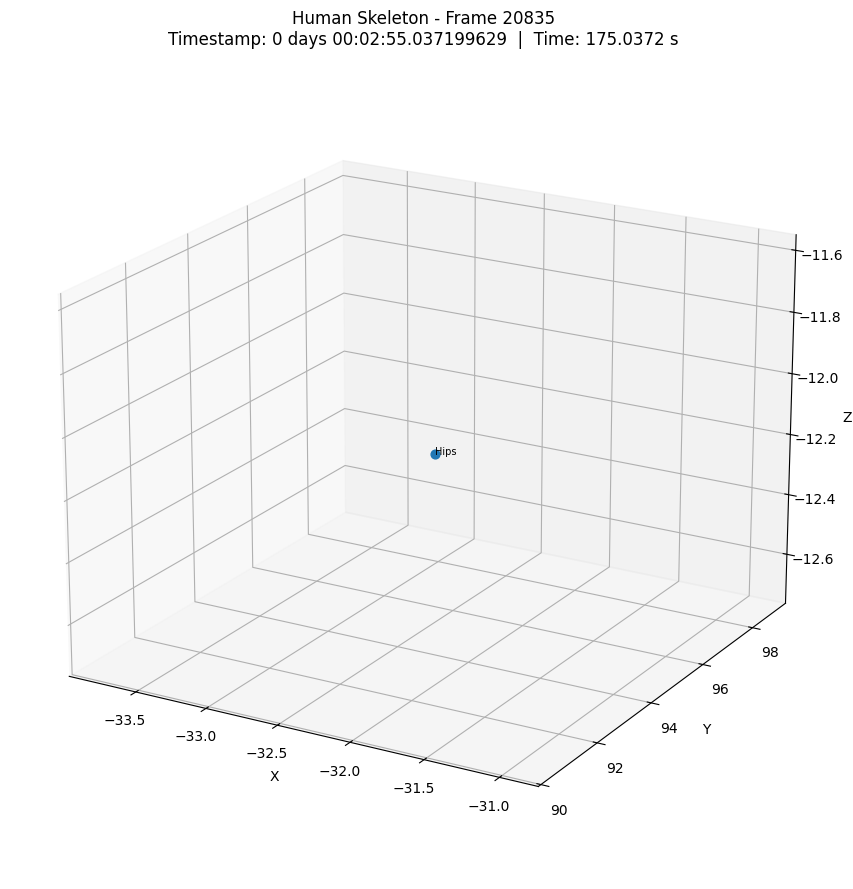

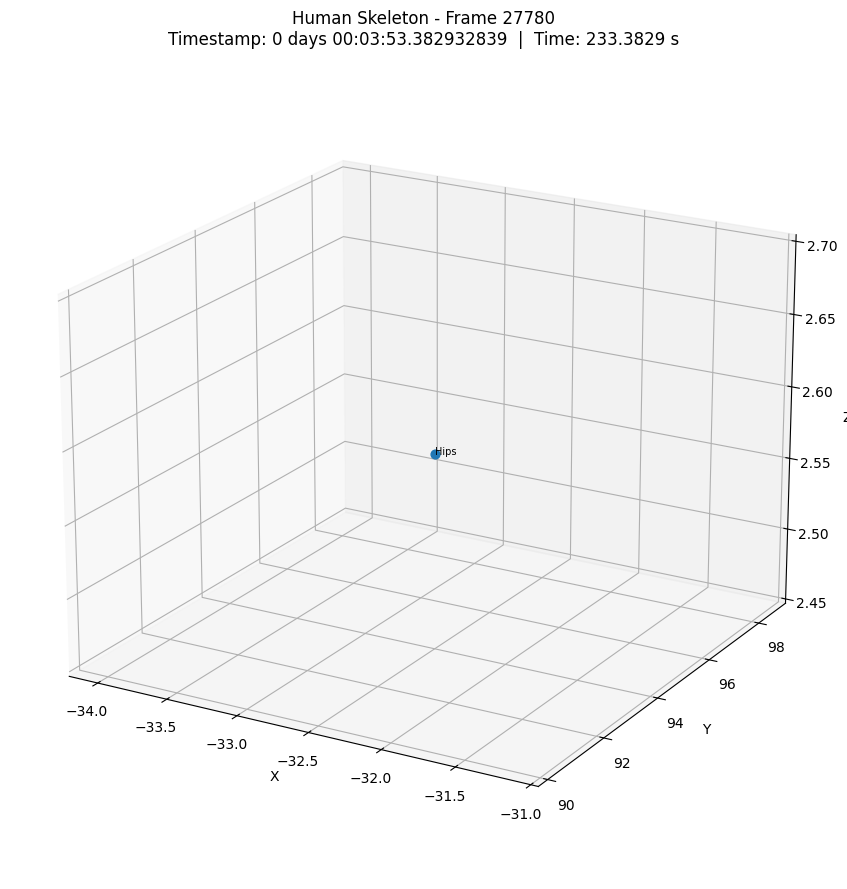

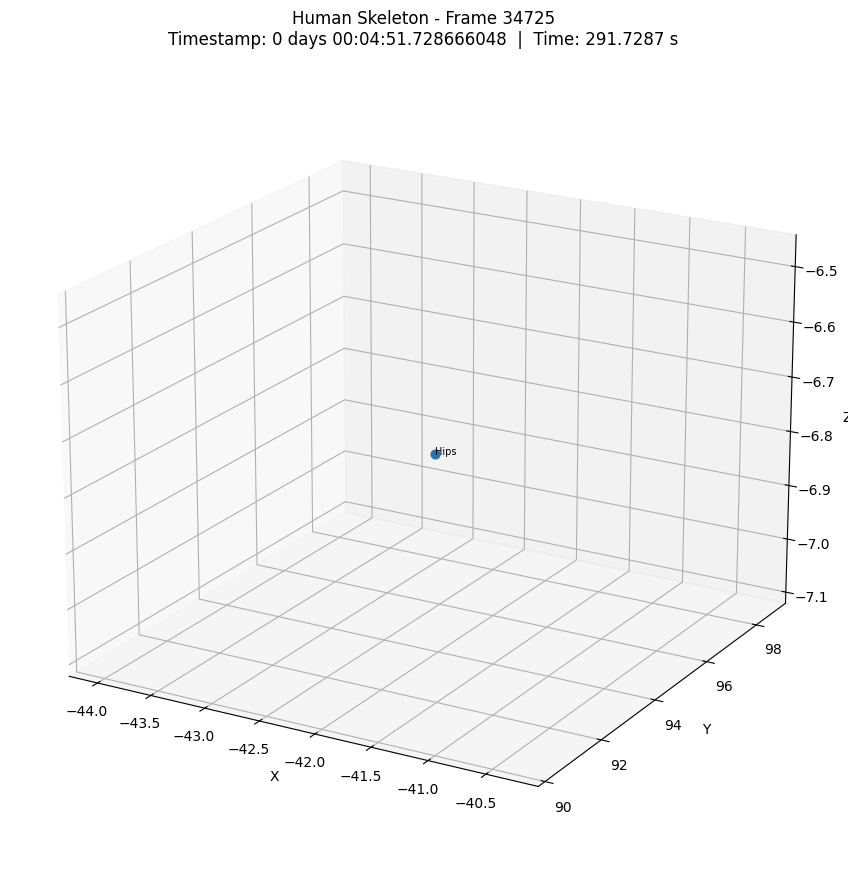

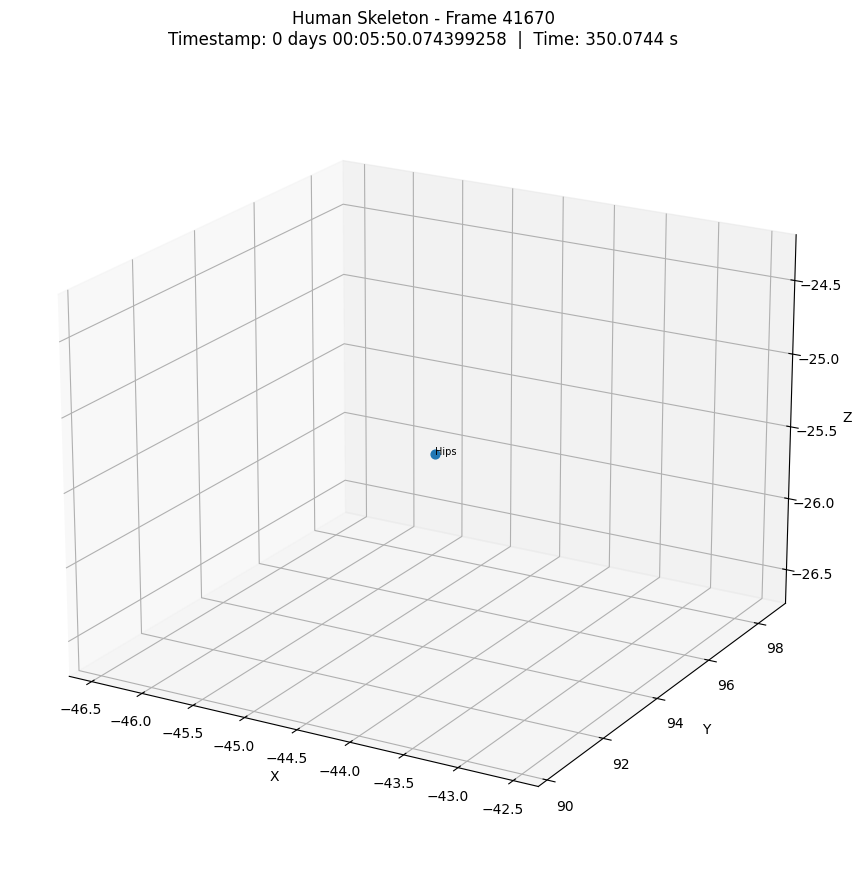

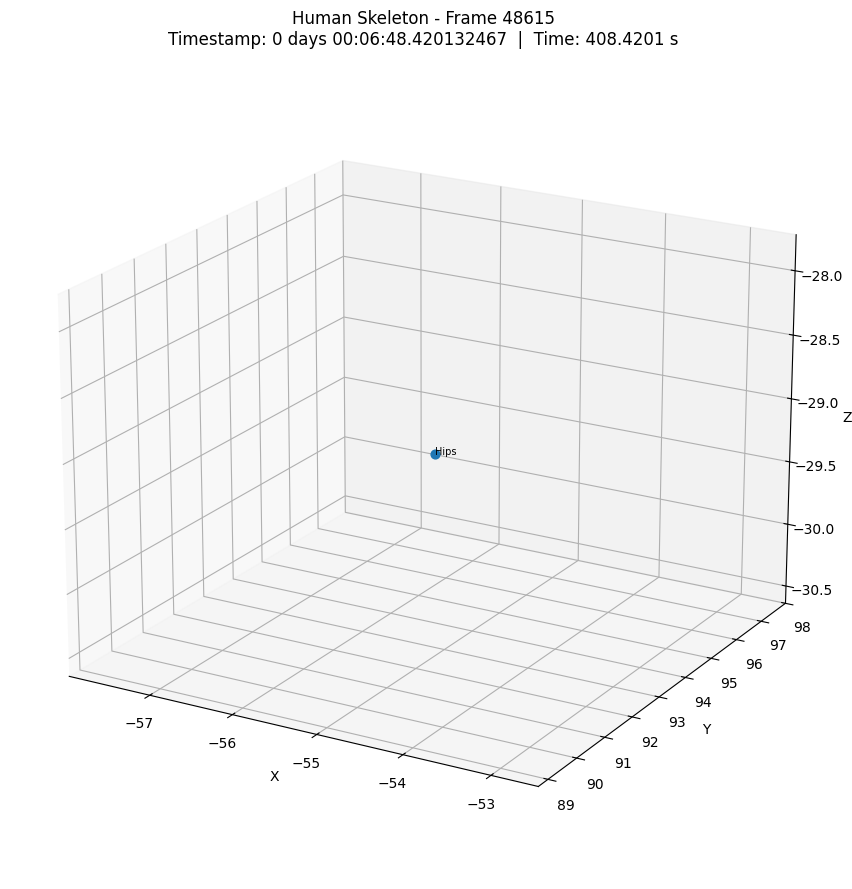

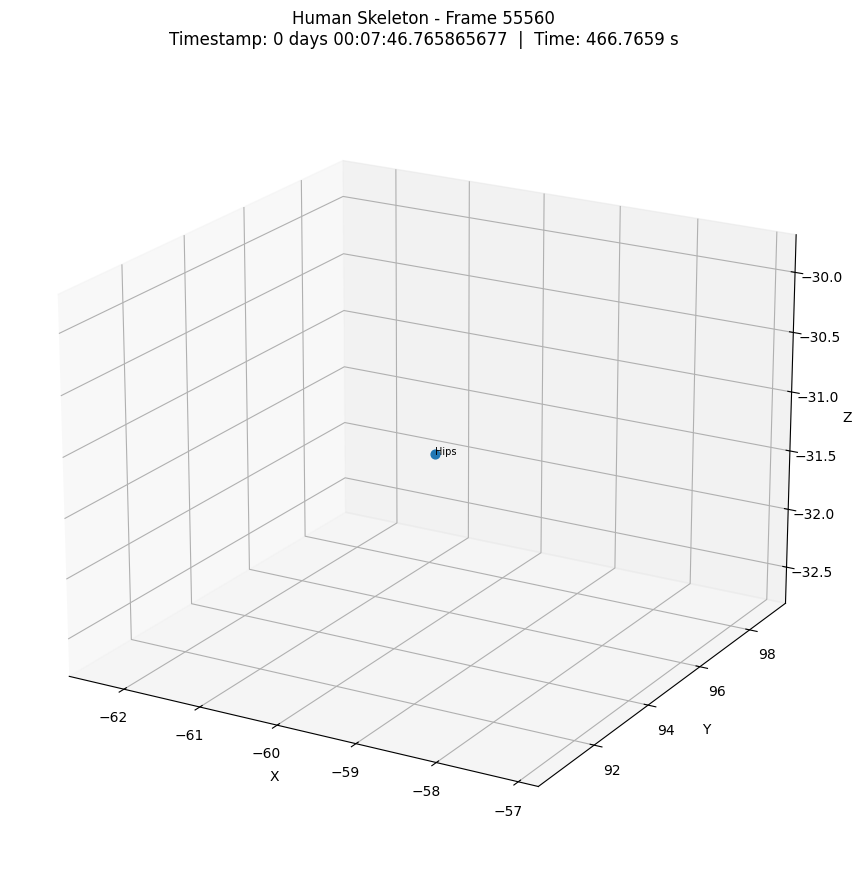

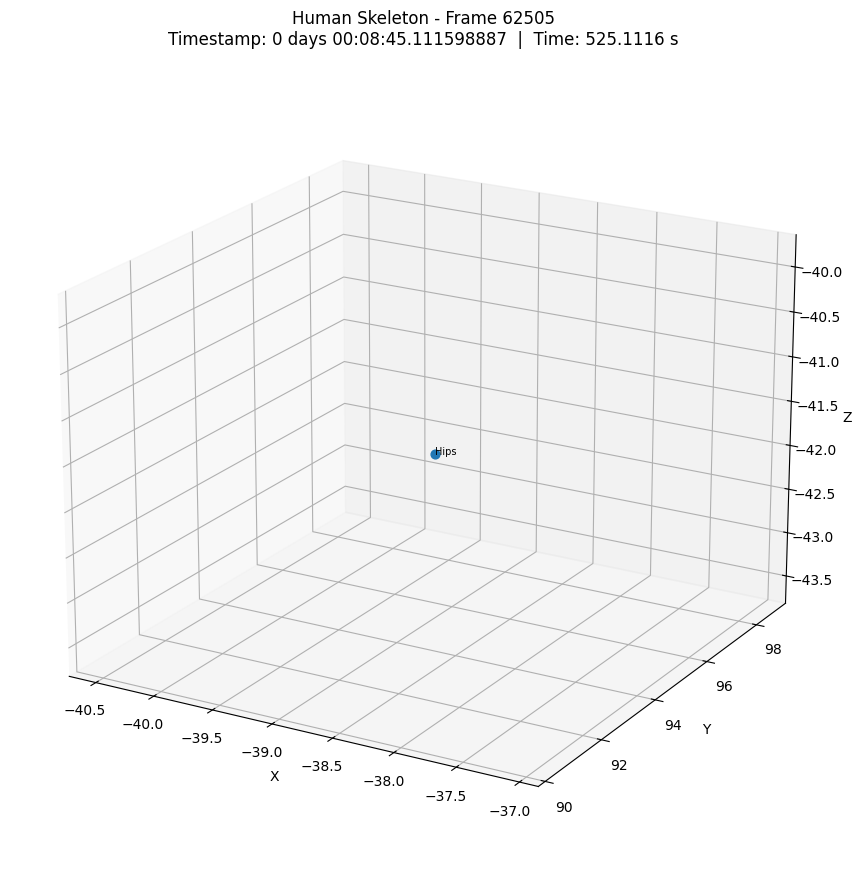


Done! Skeleton plots saved in: skeleton_plots


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# ============================================================
# 1. LOAD CSV
# ============================================================



df = pd.read_csv(file_path)

# If your timestamp is stored as a column called Timestamp,
# change this accordingly.
# For your current file, identify the timestamp column:
print(df.columns[0])

# Convert timestamp to seconds
timestamp_col = df.columns[0]

df["time_seconds"] = pd.to_timedelta(
    df[timestamp_col].astype(str)
).dt.total_seconds()


# ============================================================
# 2. DEFINE SKELETON CONNECTIONS
# ============================================================

connections = [
    # ----- Spine -----
    ("Hips", "Spine"),
    ("Spine", "Spine1"),
    ("Spine1", "Spine2"),
    ("Spine2", "Spine3"),
    ("Spine3", "Neck"),
    ("Neck", "Head"),

    # ----- Left arm -----
    ("Spine3", "LeftShoulder"),
    ("LeftShoulder", "LeftArm"),
    ("LeftArm", "LeftForeArm"),
    ("LeftForeArm", "LeftHand"),

    # ----- Right arm -----
    ("Spine3", "RightShoulder"),
    ("RightShoulder", "RightArm"),
    ("RightArm", "RightForeArm"),
    ("RightForeArm", "RightHand"),

    # ----- Left leg -----
    ("Hips", "LeftUpLeg"),
    ("LeftUpLeg", "LeftLeg"),
    ("LeftLeg", "LeftFoot"),

    # ----- Right leg -----
    ("Hips", "RightUpLeg"),
    ("RightUpLeg", "RightLeg"),
    ("RightLeg", "RightFoot"),
]


# ============================================================
# 3. FUNCTION TO GET JOINT POSITION
# ============================================================

def get_joint_position(row, joint):

    x_col = f"{joint}_Xposition"
    y_col = f"{joint}_Yposition"
    z_col = f"{joint}_Zposition"

    if x_col not in df.columns:
        return None

    if y_col not in df.columns:
        return None

    if z_col not in df.columns:
        return None

    return np.array([
        row[x_col],
        row[y_col],
        row[z_col]
    ], dtype=float)


# ============================================================
# 4. SELECT 10 TIMESTAMPS
# ============================================================

n_frames = len(df)

# If >= 10 frames, choose 10 evenly distributed frames.
# If < 10 frames, use every available frame.
if n_frames >= 10:
    frame_indices = np.linspace(
        0,
        n_frames - 1,
        10,
        dtype=int
    )
else:
    frame_indices = np.arange(n_frames)

print("Frames selected:", frame_indices)


# ============================================================
# 5. CREATE OUTPUT DIRECTORY
# ============================================================

output_dir = "skeleton_plots"
os.makedirs(output_dir, exist_ok=True)


# ============================================================
# 6. GENERATE SKELETON PLOTS
# ============================================================

for plot_number, frame_idx in enumerate(frame_indices, start=1):

    row = df.iloc[frame_idx]

    fig = plt.figure(figsize=(9, 9))
    ax = fig.add_subplot(111, projection="3d")

    # --------------------------------------------------------
    # Plot joints
    # --------------------------------------------------------

    joint_positions = {}

    for connection in connections:

        for joint in connection:

            if joint not in joint_positions:

                position = get_joint_position(row, joint)

                if position is not None and np.all(np.isfinite(position)):
                    joint_positions[joint] = position

    # Plot individual joints
    for joint, position in joint_positions.items():

        ax.scatter(
            position[0],
            position[1],
            position[2],
            s=40
        )

        ax.text(
            position[0],
            position[1],
            position[2],
            joint,
            fontsize=7
        )


    # --------------------------------------------------------
    # Draw bones
    # --------------------------------------------------------

    for joint1, joint2 in connections:

        if joint1 not in joint_positions:
            continue

        if joint2 not in joint_positions:
            continue

        p1 = joint_positions[joint1]
        p2 = joint_positions[joint2]

        ax.plot(
            [p1[0], p2[0]],
            [p1[1], p2[1]],
            [p1[2], p2[2]],
            linewidth=2
        )


    # --------------------------------------------------------
    # Timestamp
    # --------------------------------------------------------

    timestamp = df.iloc[frame_idx][timestamp_col]
    time_sec = df.iloc[frame_idx]["time_seconds"]

    ax.set_title(
        f"Human Skeleton - Frame {frame_idx}\n"
        f"Timestamp: {timestamp}  |  Time: {time_sec:.4f} s"
    )


    # --------------------------------------------------------
    # Axis labels
    # --------------------------------------------------------

    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")


    # --------------------------------------------------------
    # Make axes approximately equal
    # --------------------------------------------------------

    all_positions = np.array(
        list(joint_positions.values())
    )

    if len(all_positions) > 0:

        x_min, y_min, z_min = all_positions.min(axis=0)
        x_max, y_max, z_max = all_positions.max(axis=0)

        max_range = max(
            x_max - x_min,
            y_max - y_min,
            z_max - z_min
        ) / 2

        x_mid = (x_max + x_min) / 2
        y_mid = (y_max + y_min) / 2
        z_mid = (z_max + z_min) / 2

        ax.set_xlim(x_mid - max_range, x_mid + max_range)
        ax.set_ylim(y_mid - max_range, y_mid + max_range)
        ax.set_zlim(z_mid - max_range, z_mid + max_range)


    # --------------------------------------------------------
    # Viewing angle
    # --------------------------------------------------------

    ax.view_init(
        elev=20,
        azim=-60
    )

    plt.tight_layout()


    # --------------------------------------------------------
    # SAVE
    # --------------------------------------------------------

    output_file = os.path.join(
        output_dir,
        f"skeleton_frame_{plot_number:02d}.png"
    )

    plt.savefig(
        output_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


print(
    f"\nDone! Skeleton plots saved in: {output_dir}"
)